# 01: Data description, preprocessing and quality checks

This notebook is the data section of my PSYC 40 final project. It documents exactly what data I used, how I turned the authors' files into a model-ready format, and the checks I ran to make sure nothing was lost, misread or invented along the way.

**Dataset.** CRCNS fcx-1 (Watson, Levenstein, Greene, Gelinas & Buzsáki, 2016, *Neuron* 90:839; data doi:10.6080/K02N506Q). Rats carried 64-site silicon probes in deep layers of frontal cortex and were recorded in their home cage during the lights-on period, across natural waking and sleep.

**Guiding principle.** I use the authors' values and curation as given: their spike times, their stable-unit set, their excitatory/inhibitory labels and their sleep scoring. I never drop units or time on a metric of my own. Time is excluded only where the authors' own notes say so, or where there is no spike data.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from src.preprocess import load_processed, LABEL_CODES
pd.set_option('display.max_colwidth', 120)
qc = pd.read_csv(ROOT/'reports/qc_table.csv').sort_values(['rat','session'])
checks = pd.read_csv(ROOT/'reports/qc_checks.csv')
print(f"{len(qc)} sessions, {qc.rat.nunique()} rats, {int(qc.n_E.sum())} excitatory + {int(qc.n_I.sum())} inhibitory units")

12 sessions, 10 rats, 514 excitatory + 78 inhibitory units


## 1. What the data is

**Spikes.** The authors recorded voltage at 20 kHz, detected spikes, and sorted them into single neurons ("units"). For each unit I get the list of times it fired, in seconds, precise to 0.05 ms (every time lies on the 1/20,000 s grid). This is event data, not a regularly sampled signal. A session is naturally pictured as a raster: x = time (hours), y = unit, one tick per spike.

**The authors' labels.**
- *Per unit:* putative excitatory (E) or inhibitory (I), from spike waveform shape and, where available, confirmed by short-latency synaptic interactions with other cells ("definite" vs "waveform only"); and the probe shank the unit was recorded on.
- *Per time:* brain state, scored at 1 s resolution from the LFP spectrum (first principal component), hippocampal/cortical theta and an EMG proxy derived from the LFP, then manually reviewed. States: **WAKE** (≥7 min arousal), **nonREM** packets, **REM**, **microarousals** (<40 s arousals between nonREM packets) and **wake interruptions** (40–120 s).
- *Events:* UP/DOWN states and spindles.

**Files I use** (all MATLAB v5, plain-array formats only): `_SStable` (spike times of the authors' stable units, plus shank), `_CellIDs` (E/I labels), `_SSubtypes` and `_MeanWaveforms` (cross-checks), `.xml` + `_ChannelAnatomy.csv` (shank → channels → region), `_WSRestrictedIntervals` (state scoring), `_UPDOWNINtervals`, `_Spindles`, `_BasicMetaData`. I skipped the raw LFP (`.eeg`), which the plan does not use.

## 2. Sessions I used

In [2]:
cols = ['session','rat','regions','n_E','n_I','min_usable_WAKE','min_nonREM','min_REM','n_WAKE_to_SLEEP','n_MA','pct_seconds_scored','cleared_for_modeling']
qc[cols].rename(columns={'n_E':'E units','n_I':'I units','min_usable_WAKE':'WAKE min','min_nonREM':'nonREM min',
                         'min_REM':'REM min','n_WAKE_to_SLEEP':'WAKE→SLEEP','n_MA':'microarousals',
                         'pct_seconds_scored':'% seconds scored','cleared_for_modeling':'cleared'})

,session,rat,regions,E units,I units,WAKE min,nonREM min,REM min,WAKE→SLEEP,microarousals,% seconds scored,cleared
0,20140526_277um,B22,mPFC,51,11,35.7,45.9,3.0,2,55,49.8,True
1,BWRat17_121712,BWRat17,ACC,43,7,40.4,15.9,1.7,1,10,68.6,True
2,BWRat17_121912,BWRat17,ACC,34,1,19.7,41.8,3.8,1,70,84.6,True
3,BWRat18_020513,BWRat18,M2,34,6,33.5,69.3,10.2,2,33,97.0,True
4,BWRat19_032413,BWRat19,M2,37,13,30.6,28.9,0.0,1,57,85.8,True
5,BWRat19_032513,BWRat19,M2,51,10,7.5,18.1,3.8,1,40,62.0,True
6,BWRat20_101013,BWRat20,ACC,17,5,11.8,32.4,10.9,1,44,31.2,True
7,BWRat21_121113,BWRat21,mPFC,28,4,35.2,56.5,21.3,2,130,45.6,True
8,Bogey_012615,Bogey,mPFC,33,3,57.7,108.7,13.1,3,73,62.0,True
9,Dino_061914_mPFC,Dino,mPFC,55,5,10.5,26.6,4.9,1,43,20.3,True


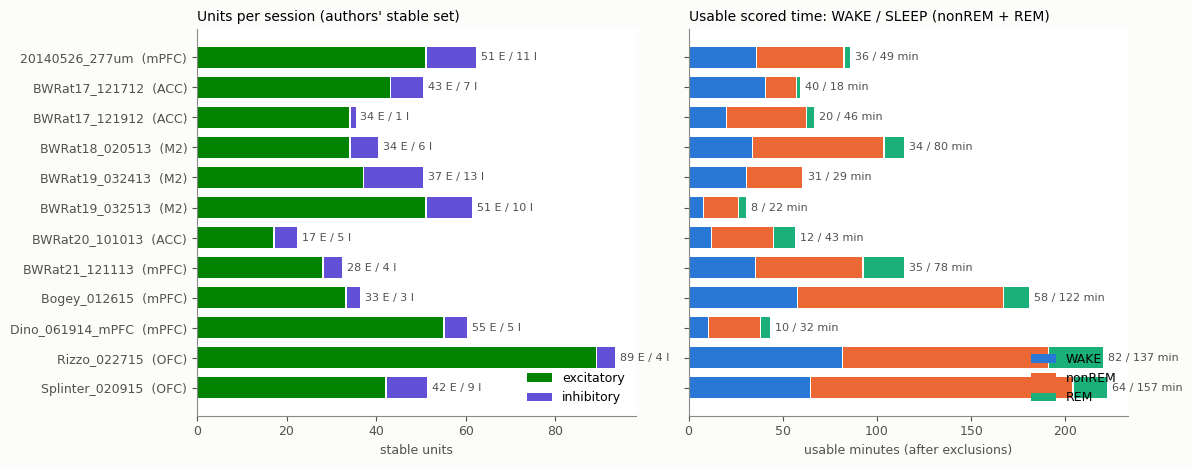

In [3]:
display(Image(filename=str(ROOT/'figures/qc/_overview.png')))

## 3. Preprocessing: what I did to make it model-ready

1. **Load as given.** Spike trains come from the authors' stable-unit set. Three loading traps are handled explicitly: (a) `scipy` collapses a one-element cell array into its contents (one session's `SiDef` loads as a single 196,195-spike train instead of a list of one train), so cell arrays are read unsqueezed; (b) a single interval loads as shape `(2,)` and is reshaped to `(1, 2)`; (c) one-element index lists load as scalars.
2. **Region by shank (a lookup, not an inference).** No file gives a per-unit region. Each unit's shank → that shank's channels (`.xml`) → each channel's region (`_ChannelAnatomy.csv`). Every shank with units lies entirely in one region, so the lookup is unambiguous. The anatomy files label BWRat18/19 as "MotorCtx"; the paper calls this region M2, and I use M2 (the file label is kept in the unit table).
3. **1 s labels (the answer key).** The authors' state intervals written out one entry per second. Seconds no interval covers stay *unscored* (neurons fire normally then; the authors simply did not assign a state outside their wake-to-sleep episodes). Seconds covered by two state types are marked *ambiguous* (no precedence rule) and are never used.
4. **End of data = last spike.** In several sessions the authors' scoring, and sometimes the recording-file metadata, extend past the last spike. Those seconds have no spike data and are never used.
5. **Exclusions from the authors' notes only.** BWRat18_020513: from 7650 s ("Big instabilities at 7650 s"); BWRat21_121113: from 22000 s ("Used only until UNSTABLE ~22000 sec"); injection sessions: everything after the recording file before the injection ends.
6. **Per-state firing rates** = spike count ÷ seconds the authors scored as that state (arithmetic only).

Output per session in `data/processed/<session>/`: `spikes.npz`, `units.csv`, `labels_1s.npz` (labels, excluded, usable), `states.npz`, `events.npz`, `meta.json`.

In [4]:
s = load_processed('BWRat20_101013')
print('units:', len(s['spikes']), '| seconds:', len(s['labels']), '| usable seconds:', int(s['usable'].sum()))
print('label codes:', LABEL_CODES)
s['units'][['unit_id','type','type_source','shank','region','n_spikes','rate_WAKE_hz','rate_nonREM_hz','rate_REM_hz']].head(8)

units: 22 | seconds: 13365 | usable seconds: 3301
label codes: {'UNSCORED': 0, 'WAKE': 1, 'nonREM': 2, 'REM': 3, 'MA': 4, 'WI': 5, 'AMBIGUOUS': 9}


,unit_id,type,type_source,shank,region,n_spikes,rate_WAKE_hz,rate_nonREM_hz,rate_REM_hz
0,1,I,waveform only,1,ACC,114488,7.029787,9.204943,15.206422
1,2,E,waveform only,1,ACC,30181,4.001418,1.540165,1.558104
2,3,E,waveform only,2,ACC,29894,2.907801,1.157570,3.425076
3,4,E,waveform only,2,ACC,5053,0.331915,0.293512,0.486239
4,5,I,definite (waveform + synaptic interaction),2,ACC,196195,14.052482,16.362513,13.223242
5,6,E,waveform only,3,ACC,7639,0.380142,0.666838,2.522936
6,7,E,waveform only,3,ACC,30094,2.493617,1.842945,3.747706
7,8,I,waveform only,3,ACC,52352,3.228369,4.708548,7.123853


## 4. Quality checks

Every check reports PASS / WARN / FAIL per session. A FAIL blocks a session from modeling; a WARN is reported and explained but changes nothing unless the authors' notes say so.

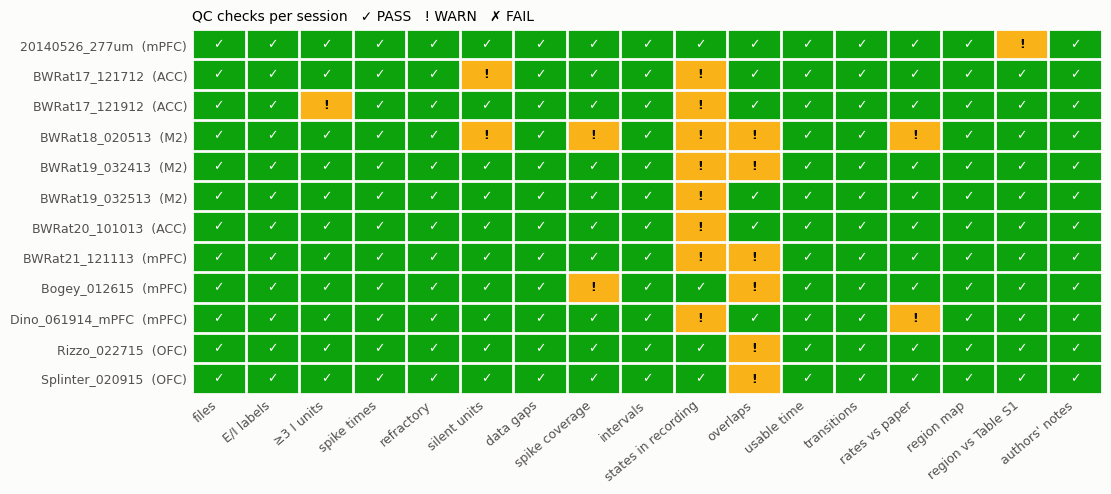

In [5]:
display(Image(filename=str(ROOT/'figures/qc/_checks_heatmap.png')))

In [6]:
flags = checks[checks.status != 'PASS'][['session','status','area','check','detail']].sort_values('session')
flags.style.hide(axis='index')

session,status,area,check,detail
20140526_277um,WARN,Anatomy,region agrees with paper Table S1,"data: mPFC; Table S1 (B22): OFC -> using the per-channel anatomy file (data), conflict noted"
BWRat17_121712,WARN,Spikes,units with zero spikes in an analyzed state,WAKE: units [36]; REM: units [33] (listed only; nothing excluded)
BWRat17_121712,WARN,States,scored states lie within the spike recording,"MA 10 s, WI 89 s scored after the spike recording ends at 6059 s -> not used"
BWRat17_121912,WARN,States,scored states lie within the spike recording,"MA 442 s, WI 632 s scored after the spike recording ends at 6535 s -> not used"
BWRat17_121912,WARN,Units,inhibitory units >= 3,1 inhibitory units (skip this session in the E-vs-I ablation)
BWRat18_020513,WARN,States,scored states lie within the spike recording,"nonREM 1 s, MA 491 s, WI 914 s scored after the spike recording ends at 7590 s -> not used"
BWRat18_020513,WARN,Spikes,spike data covers the recording files,"last spike 7590.5 s, recording files end 9388.8 s -> 1798 s at the end have no spike data and are not used"
BWRat18_020513,WARN,Spikes,units with zero spikes in an analyzed state,REM: units [28] (listed only; nothing excluded)
BWRat18_020513,WARN,States,state types do not overlap,"WAKE&MA 9 s, WAKE&WI 81 s -> marked AMBIGUOUS, excluded from modeling"
BWRat18_020513,WARN,Physiology,median rates vs Watson 2016 (comparison only),E WAKE 0.67 Hz (paper 0.76); E nonREM 0.44 Hz (paper 0.69); E REM 0.25 Hz (paper 0.88); I WAKE 1.92 Hz (paper 5.59); I nonREM 0.15 Hz (paper 4.69); I REM 0.06 Hz (paper 4.25); I median <= E median in nonREM; I median <= E median in REM


**Unit counts against the paper.** Supplementary Table S1 gives each rat's mean E and I units per session. For every rat whose sessions are all here, my counts must match exactly.

In [7]:
from src.reference import TABLE_S1
rows = []
for rat, g in qc.groupby('rat'):
    r = TABLE_S1[rat]
    rows.append(dict(rat=rat, sessions=len(g), sessions_in_paper=r['n_sessions'],
                     E_mine=round(g.n_E.mean(),1), E_paper=r['pE'], I_mine=round(g.n_I.mean(),1), I_paper=r['pI'],
                     verdict=('MATCH' if abs(g.n_E.mean()-r['pE'])<0.06 and abs(g.n_I.mean()-r['pI'])<0.06 else 'MISMATCH')
                             if len(g)==r['n_sessions'] else 'partial'))
pd.DataFrame(rows)

,rat,sessions,sessions_in_paper,E_mine,E_paper,I_mine,I_paper,verdict
0,B22,1,3,51.0,34.0,11.0,7.3,partial
1,BWRat17,2,2,38.5,38.5,4.0,4.0,MATCH
2,BWRat18,1,1,34.0,34.0,6.0,6.0,MATCH
3,BWRat19,2,2,44.0,44.0,11.5,11.5,MATCH
4,BWRat20,1,2,17.0,38.5,5.0,5.5,partial
5,BWRat21,1,3,28.0,19.7,4.0,2.0,partial
6,Bogey,1,1,33.0,33.0,3.0,3.0,MATCH
7,Dino,1,8,55.0,41.8,5.0,3.9,partial
8,Rizzo,1,2,89.0,57.0,4.0,2.5,partial
9,Splinter,1,2,42.0,33.5,9.0,5.5,partial


**Firing rates against the paper.** Watson 2016 reports median rates of excitatory cells of 0.76 / 0.69 / 0.88 Hz (WAKE / nonREM / REM) and of inhibitory cells of 5.59 / 4.69 / 4.25 Hz. Pooled over my sessions:

In [8]:
units = pd.concat([load_processed(x)['units'] for x in qc.session])
med = units.groupby('type')[['rate_WAKE_hz','rate_nonREM_hz','rate_REM_hz']].median().round(2)
med['n_units'] = units.groupby('type').size()
med

,rate_WAKE_hz,rate_nonREM_hz,rate_REM_hz,n_units
type,,,,
E,0.80,0.67,0.85,514
I,5.51,4.64,7.12,78


## 5. Example sessions (one per Phase 1 session)

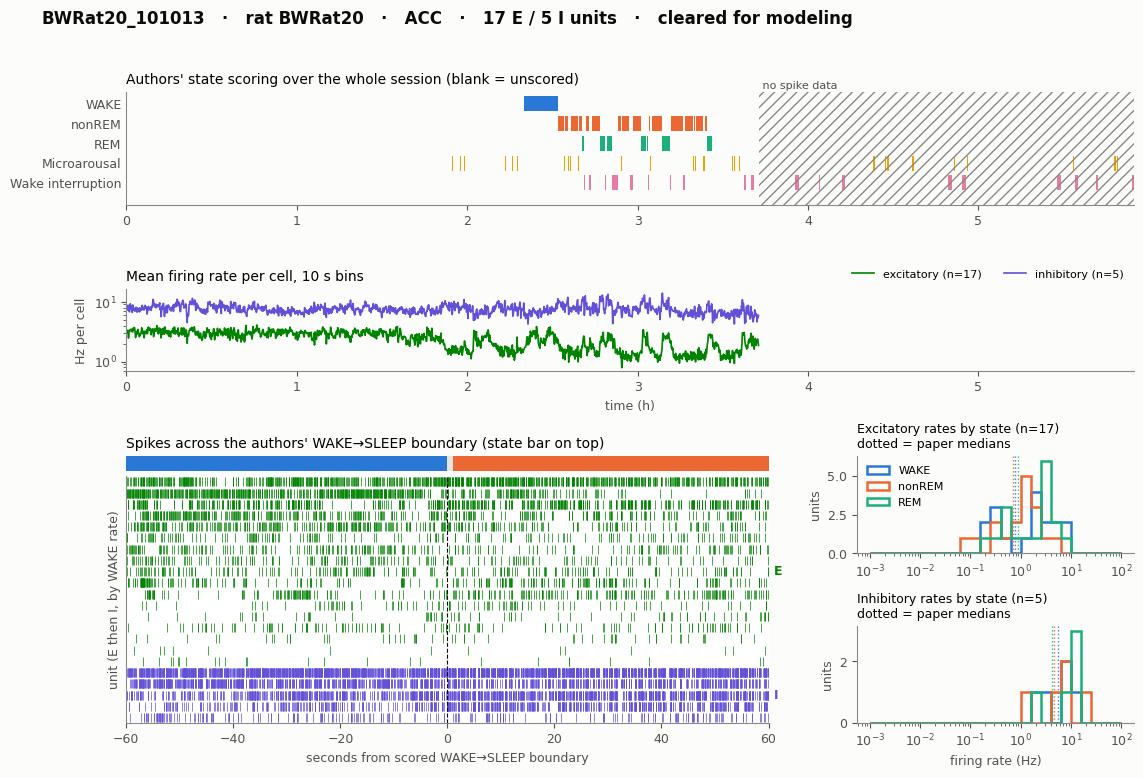

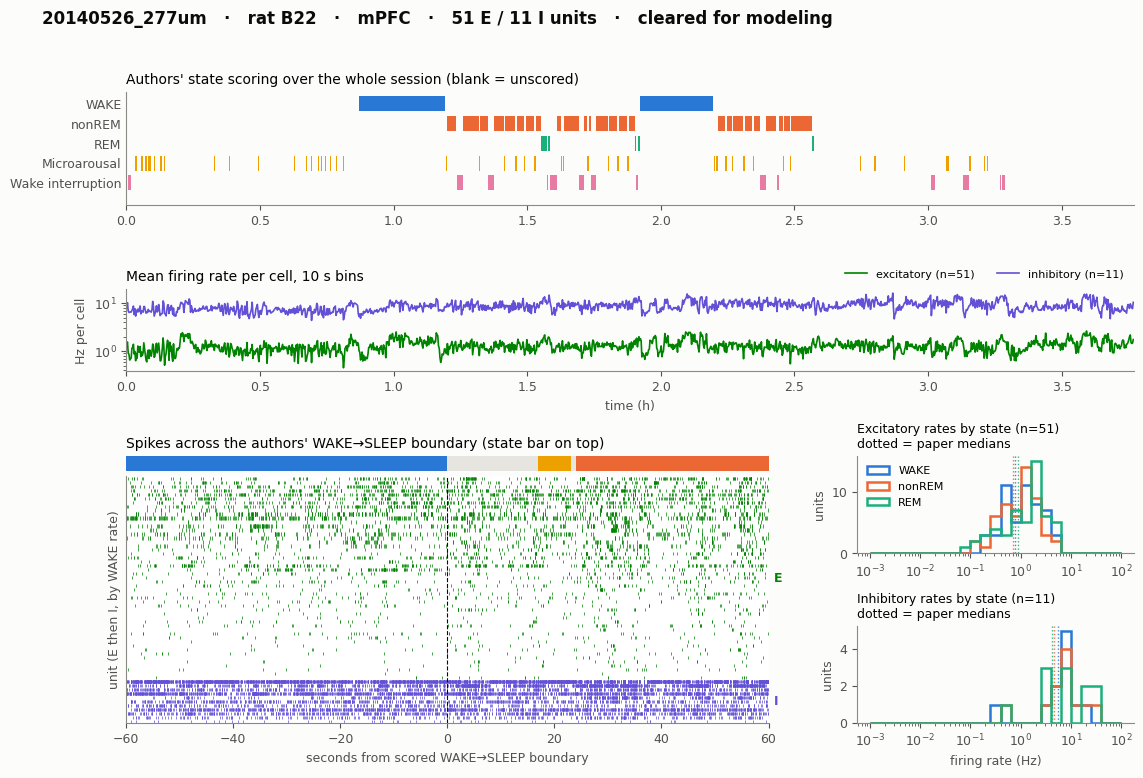

In [9]:
for x in ['BWRat20_101013', '20140526_277um']:
    display(Image(filename=str(ROOT/f'figures/qc/{x}.png')))

## 6. What the data can and cannot support

- **Labels and inputs share signal.** The authors scored states from LFP recorded on the same probes as the spikes, and the main scoring signal (LFP PC1) tracks the same UP/DOWN alternation that appears as spike synchrony. High decoding accuracy is expected partly for this reason.
- **WAKE means active wake.** WAKE labels cover only arousals of ≥7 min, which the authors chose because they go with active behavior; microarousals and wake interruptions are excluded from the WAKE/SLEEP labels.
- **Lights-on recordings, deep layers, frontal cortex only.**
- **Region and rat are confounded.** Each rat contributes one region (Dino contributes ACC and mPFC as separate recordings). One conflict: Table S1 lists rat B22 as OFC while its anatomy files and the authors' spreadsheet say mPFC; I follow the anatomy files.
- **Same-rat sessions mostly record different neurons** (probes advanced up to 300 µm/day), which is one more reason to split training and testing by rat.

The full interactive report with every session's panel is `reports/qc_report.html`.